In [18]:
from typing import TypedDict, Annotated
import operator

from pydantic import BaseModel, Field
from langchain_groq import ChatGroq
from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv
from IPython.display import Image, display

load_dotenv()

llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0,
    max_tokens=180
)

In [19]:
from pydantic import BaseModel, Field

class Evaluation(BaseModel):
    score: float = Field(ge=0, le=10, description="Score out of 10")
    feedback: str = Field(description="One short feedback sentence")

structured_llm = llm.with_structured_output(
    Evaluation,
    method="json_schema"
)

In [20]:
class EssayState(TypedDict):
    essay: str
    evaluations: Annotated[list[dict], operator.add]
    average_score: float
    final_feedback: str

In [21]:
def evaluate_clarity(state: EssayState):
    result = structured_llm.invoke(
        f"Evaluate clarity of thought in this UPSC essay. "
        f"Give a score and one short feedback sentence:\n{state['essay']}"
    )

    return {
        "evaluations": [
            {"aspect": "Clarity", **result.model_dump()}
        ]
    }


def evaluate_depth(state: EssayState):
    result = structured_llm.invoke(
        f"Evaluate depth of analysis in this UPSC essay. "
        f"Give a score and one short feedback sentence:\n{state['essay']}"
    )

    return {
        "evaluations": [
            {"aspect": "Depth", **result.model_dump()}
        ]
    }


def evaluate_language(state: EssayState):
    result = structured_llm.invoke(
        f"Evaluate language quality in this UPSC essay. "
        f"Give a score and one short feedback sentence:\n{state['essay']}"
    )

    return {
        "evaluations": [
            {"aspect": "Language", **result.model_dump()}
        ]
    }

In [22]:
def final_evaluation(state: EssayState):
    evaluations = state["evaluations"]

    average = sum(e["score"] for e in evaluations) / len(evaluations)

    feedback = "\n".join(
        f"{e['aspect']}: {e['feedback']}"
        for e in evaluations
    )

    response = llm.invoke(
        f"Summarize this UPSC essay feedback in 2 short sentences:\n{feedback}"
    )

    return {
        "average_score": round(average, 2),
        "final_feedback": response.content
    }

In [23]:
graph = StateGraph(EssayState)

graph.add_node("clarity", evaluate_clarity)
graph.add_node("depth", evaluate_depth)
graph.add_node("language", evaluate_language)
graph.add_node("final_evaluation", final_evaluation)

# Parallel branches
graph.add_edge(START, "clarity")
graph.add_edge(START, "depth")
graph.add_edge(START, "language")

# Join all three branches
graph.add_edge(
    ["clarity", "depth", "language"],
    "final_evaluation"
)

graph.add_edge("final_evaluation", END)

workflow = graph.compile()

In [24]:
initial_state = {
    "essay": """
    Education is essential for national development.
    It reduces poverty and creates opportunities.
    However, rural areas still lack quality schools.
    Improving teacher training and infrastructure
    can help build a more equal society.
    """,
    "evaluations": []
}

final_state = workflow.invoke(initial_state)

for evaluation in final_state["evaluations"]:
    print(f"{evaluation['aspect']}: {evaluation['score']}/10")
    print(f"Feedback: {evaluation['feedback']}\n")

print("Average Score:", final_state["average_score"], "/10")
print("Final Feedback:", final_state["final_feedback"])

Clarity: 7.0/10
Feedback: Clear and concise, but could benefit from more specific examples.

Depth: 3.0/10
Feedback: Essay lacks depth and supporting evidence.

Language: 7.0/10
Feedback: Clear and concise, but could use more varied sentence structure.

Average Score: 5.67 /10
Final Feedback: The essay is clear and concise but needs more specific examples and deeper supporting evidence. Its language is good, yet varied sentence structures would improve readability.


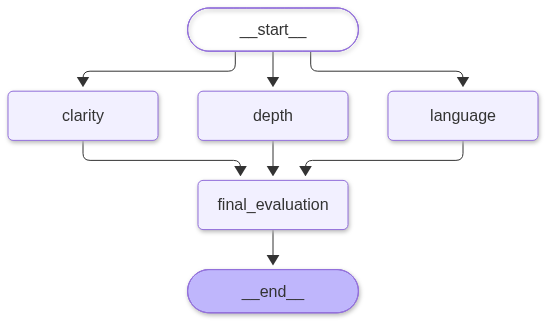

In [25]:
display(Image(workflow.get_graph().draw_mermaid_png()))